In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Cargamos ls 190 variables
X_train_muestra = np.load('train_data.npy', mmap_mode='r')


In [3]:

fin_de_X = X_train_muestra.offset + X_train_muestra.nbytes

with open('train_data.npy', 'rb') as f:
    f.seek(fin_de_X)          # Movemos el "cursor" de lectura directamente al inicio de 'y'
    y_completo = np.load(f)   # Cargamos 'y' al instante

In [4]:
X_train_muestra.offset

128

In [5]:
nombre_columnas = [
    "charge", "p", "cosTheta", "phi", "kaonID", "elecID", "muonID", "protID",
    "nCDCHits", "nPXDHits", "nSVDHits", "dz", "dr", "chiProb", "EW90", 
    "recoilMassSqrd", "pMissCMS", "cosThetaMissCMS", "cosTPTO"
]

#Lista de las 190 nombres de variables
column_names = [f"T{i}_{nombre}" for i in range(1, 11) for nombre in nombre_columnas]
df= pd.DataFrame(X_train_muestra, columns=column_names, dtype='float32')
df['target_flavor'] = y_completo.astype('int8')

In [6]:
df.head(5)
# Calcular los porcentajes de la columna 'target_sabor'
conteo = df['target_flavor'].value_counts(normalize=True) * 100

print("Distribución de Clases:")
print(f"B0 (Positivos - 1): {conteo[1]:.2f}%")
print(f"anti-B0 (Negativos - 0): {conteo[0]:.2f}%")
print(f"tamanio de la muestra:{df.shape}")

Distribución de Clases:
B0 (Positivos - 1): 50.02%
anti-B0 (Negativos - 0): 49.98%
tamanio de la muestra:(5850186, 191)


In [7]:
df_eda = df.sample(n=500000, random_state=42)

In [8]:
# Calcular los porcentajes de la columna 'target_sabor'
conteo = df_eda['target_flavor'].value_counts(normalize=True) * 100

print("Distribución de Clases:")
print(f"B0 (Positivos - 1): {conteo[1]:.2f}%")
print(f"anti-B0 (Negativos - 0): {conteo[0]:.2f}%")
print(f"tamanio de la muestra:{df_eda.shape}")

Distribución de Clases:
B0 (Positivos - 1): 50.01%
anti-B0 (Negativos - 0): 49.99%
tamanio de la muestra:(500000, 191)


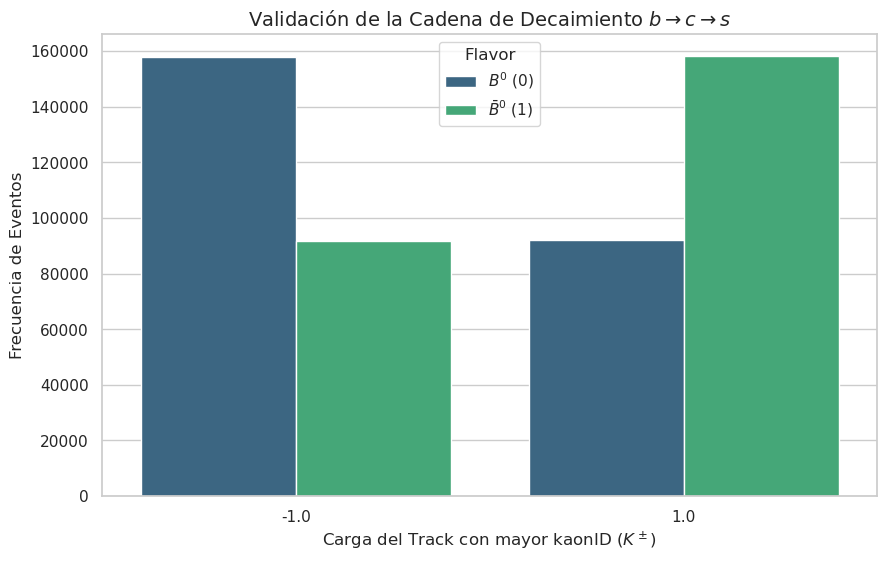

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 1. Identificar la traza con el kaonID máximo por evento
kaon_id_cols = [f"T{i}_kaonID" for i in range(1, 11)]
df_eda['leading_kaon_idx'] = df_eda[kaon_id_cols].idxmax(axis=1)

# 2. Extraer el número de la traza de forma segura (ej. 'T5_kaonID' -> 5)
# Usamos r'T(\d+)' para capturar específicamente el número del track
df_eda['track_num'] = df_eda['leading_kaon_idx'].str.extract(r'T(\d+)').astype(float).astype(int)

# 3. Obtener la carga de esa traza específica utilizando indexación avanzada de Numpy
# Esto es vital para manejar los 750,000 eventos eficientemente
charge_cols = [f"T{i}_charge" for i in range(1, 11)]
charge_matrix = df_eda[charge_cols].values
df_eda['leading_kaon_charge'] = charge_matrix[np.arange(len(df_eda)), df_eda['track_num'] - 1]

# 4. Graficar la distribución por sabor (Flavor Tagging)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Countplot para las cargas discretas (-1, 1)
ax = sns.countplot(data=df_eda, x='leading_kaon_charge', hue='target_flavor', palette='viridis')

# Estética y etiquetas basadas en el "Belle II Physics Book"
plt.title(r'Validación de la Cadena de Decaimiento $b \to c \to s$', fontsize=14)
plt.xlabel('Carga del Track con mayor kaonID ($K^\pm$)', fontsize=12)
plt.ylabel('Frecuencia de Eventos', fontsize=12)
plt.legend(title='Flavor', labels=[r'$B^0$ (0)', r'$\bar{B}^0$ (1)'])

plt.show()

In [10]:
df_eda.columns
df_eda.shape

(500000, 194)

In [11]:
#df_eda= df_eda.drop(columns=['target_flavor'])
recoil_cols = [f"T{i}_recoilMassSqrd" for i in range(1, 11)]

df_eda['sum_recoilMassSqrd_total'] = df_eda[recoil_cols].mean(axis=1)*15
#df_eda['sum_pMissCMS'] = df_eda[recoil_cols].mean(axis=1)
#pMissCMS

/tmp/ipykernel_14450/949309013.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtrado['tipo_partícula'] = df_filtrado['target_flavor'].map({0: 'Anti-Mesón', 1: 'Mesón'})


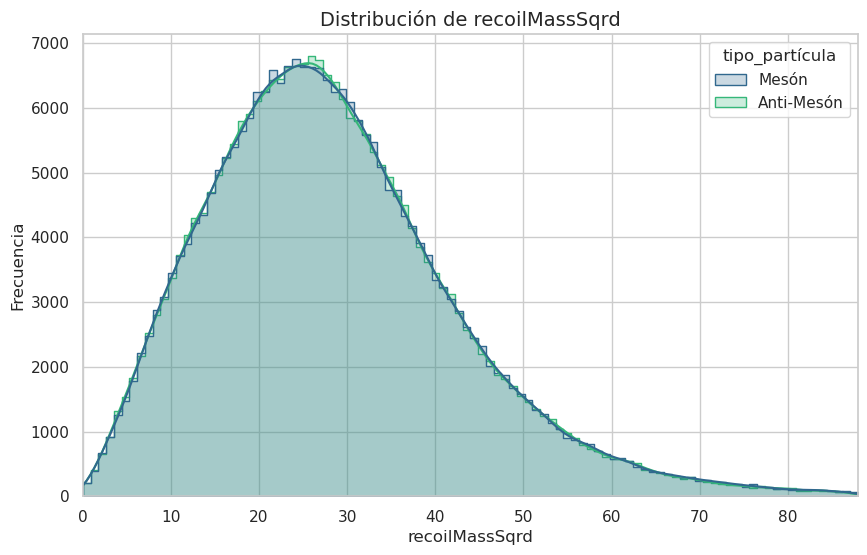

In [12]:
import numpy as np
import seaborn as sns
# 1. Calculamos el percentil 99 para ignorar el 1% de valores extremos
limite_superior = np.percentile(df_eda['sum_recoilMassSqrd_total'], 99)

df_filtrado = df_eda[df_eda['sum_recoilMassSqrd_total'] <= limite_superior]

df_filtrado['tipo_partícula'] = df_filtrado['target_flavor'].map({0: 'Anti-Mesón', 1: 'Mesón'})

plt.figure(figsize=(10, 6))

# 2. Graficamos limitando el rango (clip)
sns.histplot(data=df_filtrado, x='sum_recoilMassSqrd_total', hue='tipo_partícula', 
             kde=True, element="step", palette="viridis", bins=100,
             binrange=(0, limite_superior)) #zoom

plt.xlim(0, limite_superior) 

# 3. Opcional: Si la diferencia de frecuencia es muy grande, usa escala logarítmica
# plt.yscale('log') 

plt.title('Distribución de recoilMassSqrd', fontsize=14)
plt.xlabel(r'recoilMassSqrd', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.show()

In [13]:
limite_superior = np.percentile(df_eda['sum_pMissCMS'], 99)

plt.figure(figsize=(10, 6))

# 2. Graficamos limitando el rango (clip)
sns.histplot(data=df_eda, x='sum_pMissCMS', hue='target_flavor', 
             kde=True, element="step", palette="viridis", bins=100,
             binrange=(0, limite_superior)) # <--- Esto hace el zoom

plt.xlim(0, limite_superior) 

# 3. Opcional: Si la diferencia de frecuencia es muy grande, usa escala logarítmica
# plt.yscale('log') 

plt.title('Distribución de la Suma de pMissCMS (Zoom al 99% de los datos)', fontsize=14)
plt.xlabel(r'$\sum T_i\_pMissCMS$', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.show()

KeyError: 'sum_pMissCMS'

Categoría    | Valor del Pico (X)
-----------------------------------
_child1      | 25.6270 GeV²/c⁴
_child3      | 24.7433 GeV²/c⁴


/tmp/ipykernel_7680/1935455764.py:71: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Partícula')


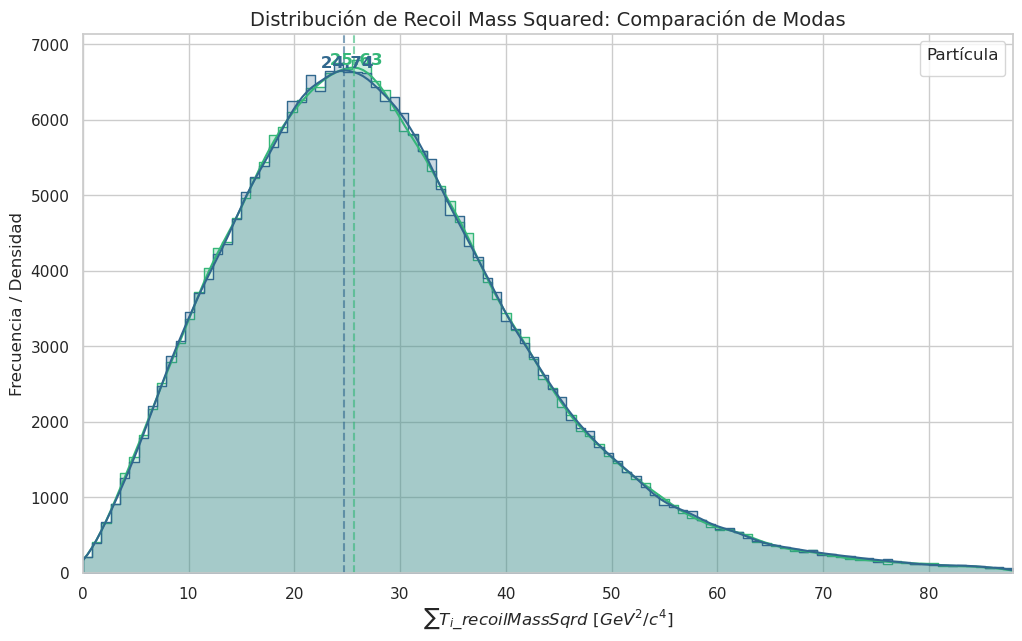

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparación de datos y filtrado de outliers (Percentil 99)
variable = 'sum_recoilMassSqrd_total'
limite_superior = np.percentile(df_eda[variable], 99)

# Creamos una copia filtrada para no afectar el dataframe original
df_filtrado = df_eda[df_eda[variable] <= limite_superior].copy()

# 2. Mapeo de etiquetas para la leyenda (0: Mesón, 1: Antimesón)
df_filtrado['tipo_particula'] = df_filtrado['target_flavor'].map({0: 'Mesón', 1: 'Antimesón'})

# 3. Configuración estética de la gráfica
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# 4. Generar el histograma con KDE (Kernel Density Estimation)
# Guardamos el objeto 'ax' para poder extraer los datos de las curvas después
ax = sns.histplot(
    data=df_filtrado, 
    x=variable, 
    hue='tipo_particula', 
    kde=True, 
    element="step", 
    palette="viridis", 
    bins=100,
    binrange=(0, limite_superior)
)

# 5. Extracción y marcado de los picos (Modas)
# ax.get_lines() contiene las curvas de densidad generadas por el KDE
lineas_kde = ax.get_lines()

print(f"{'Categoría':<12} | {'Valor del Pico (X)':<18}")
print("-" * 35)

for line in lineas_kde:
    # Extraemos las coordenadas X e Y de la curva de densidad
    xd = line.get_xdata()
    yd = line.get_ydata()
    
    # Encontramos el índice donde la densidad (Y) es máxima
    idx_max = np.argmax(yd)
    pico_x = xd[idx_max]
    pico_y = yd[idx_max]
    
    # Obtenemos el nombre de la categoría (Mesón o Antimesón)
    label = line.get_label()
    color = line.get_color()
    
    # Imprimir el valor exacto en la consola
    print(f"{label:<12} | {pico_x:.4f} GeV²/c⁴")
    
    # Dibujar línea vertical en el pico correspondiente
    plt.axvline(x=pico_x, color=color, linestyle='--', alpha=0.6, linewidth=1.5)
    
    # Añadir el valor numérico sobre el pico en la gráfica
    plt.text(
        pico_x, pico_y, f' {pico_x:.2f}', 
        color=color, fontweight='bold', va='bottom', ha='center'
    )

# 6. Finalización de etiquetas y visualización
plt.title('Distribución de Recoil Mass Squared: Comparación de Modas', fontsize=14)
plt.xlabel(r'$\sum T_i\_recoilMassSqrd$ [$GeV^2/c^4$]', fontsize=12)
plt.ylabel('Frecuencia / Densidad', fontsize=12)
plt.xlim(0, limite_superior)
plt.legend(title='Partícula')

plt.show()

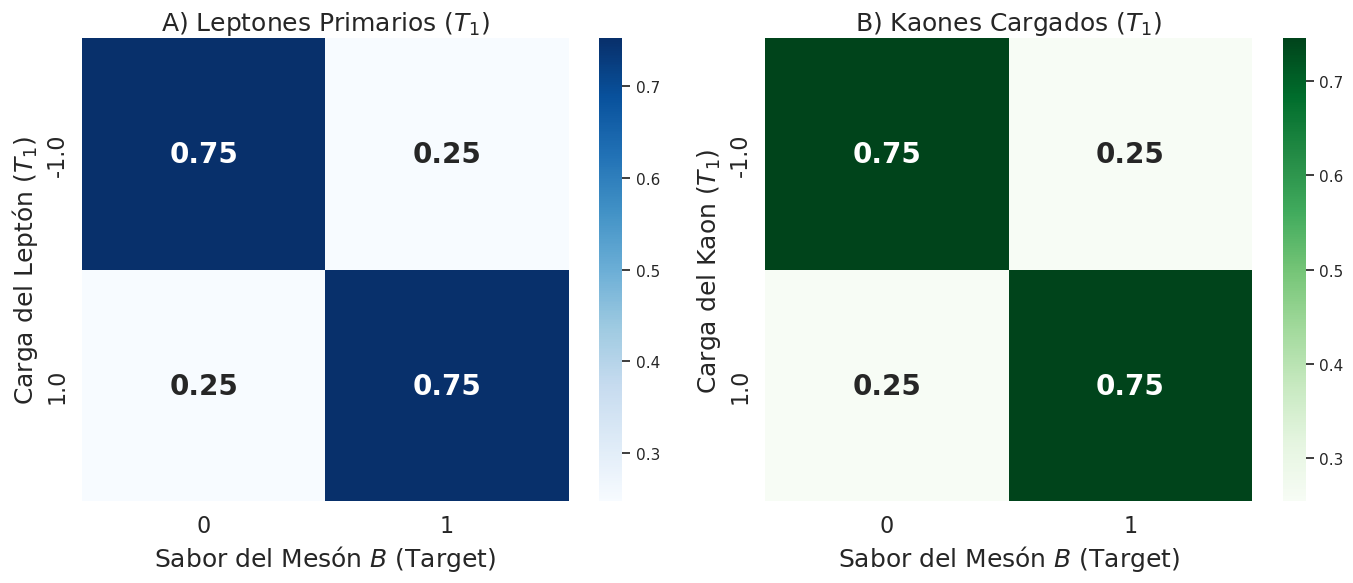

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Preparación de los sub-datasets (Filtros de alta pureza PID > 0.9)
leptones = df_eda[(df_eda['T1_elecID'] > 0.9) | (df_eda['T1_muonID'] > 0.9)].copy()
kaones = df_eda[df_eda['T1_kaonID'] > 0.9].copy()

# 2. Creación de la figura comparativa (Solo Matrices)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Matriz A: Leptones
ct_lep = pd.crosstab(leptones['T1_charge'], leptones['target_flavor'], normalize='index')
sns.heatmap(ct_lep, annot=True, cmap='Blues', fmt=".2f", ax=axes[0], annot_kws={"size": 20, "weight": "bold"})
axes[0].set_title('A) Leptones Primarios ($T_1$)', fontsize=18)
axes[0].set_xlabel('Sabor del Mesón $B$ (Target)', fontsize =18)
axes[0].set_ylabel('Carga del Leptón ($T_1$)', fontsize =18)
axes[0].tick_params(axis='both', which='major', labelsize=16) # <--- Números de los ejes (0, 1, -1)

# Matriz B: Kaones
ct_kaon = pd.crosstab(kaones['T1_charge'], kaones['target_flavor'], normalize='index')
sns.heatmap(ct_kaon, annot=True, cmap='Greens', fmt=".2f", ax=axes[1], annot_kws={"size": 20, "weight": "bold"})
axes[1].set_title('B) Kaones Cargados ($T_1$)', fontsize=18)
axes[1].set_xlabel('Sabor del Mesón $B$ (Target)', fontsize =18)
axes[1].set_ylabel('Carga del Kaon ($T_1$)', fontsize =18)
axes[1].tick_params(axis='both', which='major', labelsize=16) # <--- Números de los ejes (0, 1, -1)

plt.tight_layout()
plt.show()

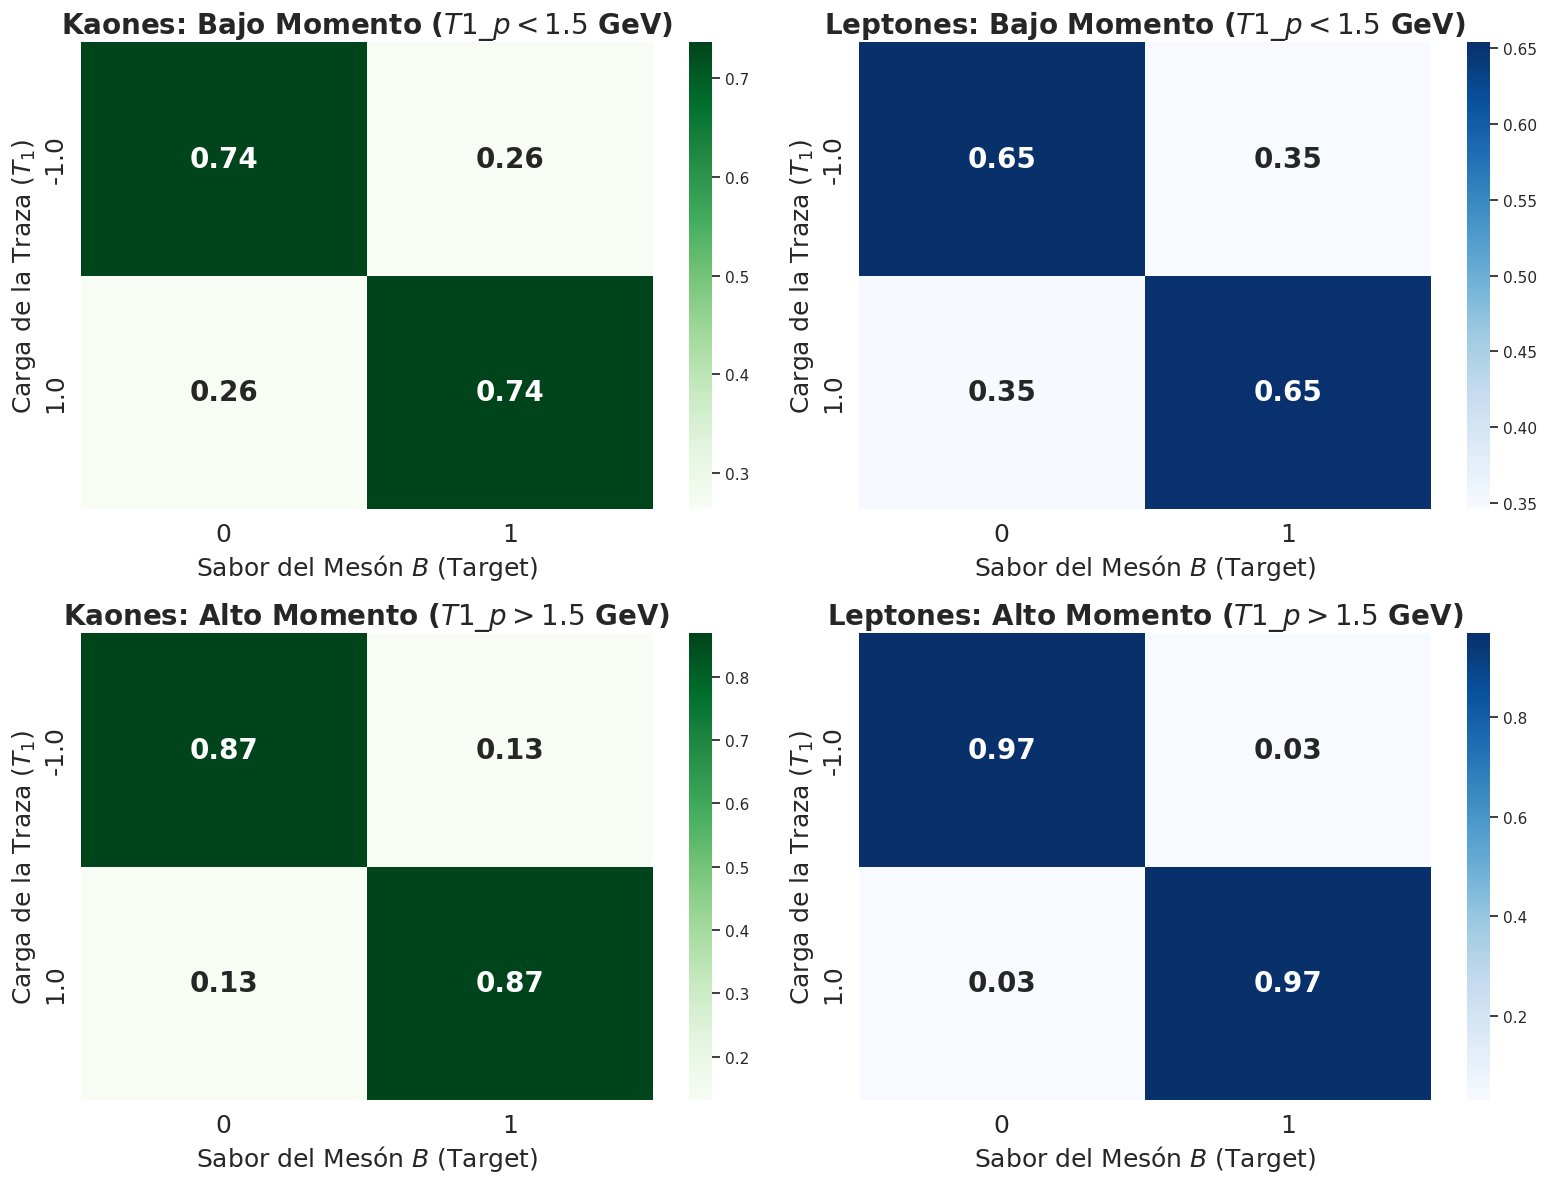

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# sub-datasets filtrados por PID
leptones_all = df_eda[(df_eda['T1_elecID'] > 0.9) | (df_eda['T1_muonID'] > 0.9)].copy()
kaones_all = df_eda[df_eda['T1_kaonID'] > 0.9].copy()

# Definición de umbrales de momento
p_bajo = 1.5
p_alto = 1.5

# Creación del Mosaico 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# BAJO MOMENTO 
# Izquierda: Kaones
low_kaon = kaones_all[kaones_all['T1_p'] < p_bajo]
ct_lk = pd.crosstab(low_kaon['T1_charge'], low_kaon['target_flavor'], normalize='index')
sns.heatmap(ct_lk, annot=True, cmap='Greens', fmt=".2f", ax=axes[0, 0],  annot_kws={"size": 20, "weight": "bold"})
axes[0, 0].set_title(f'Kaones: Bajo Momento ($T1\_p < {p_bajo}$ GeV)', fontsize=20,  fontweight = 'bold')
axes[0, 0].tick_params(axis='both', which='major', labelsize=18) # <--- Números de los ejes (0, 1, -1)

# Derecha: Leptones
low_lep = leptones_all[leptones_all['T1_p'] < p_bajo]
ct_ll = pd.crosstab(low_lep['T1_charge'], low_lep['target_flavor'], normalize='index')
sns.heatmap(ct_ll, annot=True, cmap='Blues', fmt=".2f", ax=axes[0, 1],  annot_kws={"size": 20, "weight": "bold"})
axes[0, 1].set_title(f'Leptones: Bajo Momento ($T1\_p < {p_bajo}$ GeV)', fontsize=20,  fontweight = 'bold')
axes[0, 1].tick_params(axis='both', which='major', labelsize=18) # <--- Números de los ejes (0, 1, -1)


# ALTO MOMENTO 
# Izquierda: Kaones
high_kaon = kaones_all[kaones_all['T1_p'] > p_alto]
ct_hk = pd.crosstab(high_kaon['T1_charge'], high_kaon['target_flavor'], normalize='index')
sns.heatmap(ct_hk, annot=True, cmap='Greens', fmt=".2f", ax=axes[1, 0],  annot_kws={"size": 20, "weight": "bold"})
axes[1, 0].set_title(f'Kaones: Alto Momento ($T1\_p > {p_alto}$ GeV)', fontsize=20,  fontweight = 'bold')
axes[1, 0].tick_params(axis='both', which='major', labelsize=18) # <--- Números de los ejes (0, 1, -1)


# Derecha: Leptones
high_lep = leptones_all[leptones_all['T1_p'] > p_alto]
ct_hl = pd.crosstab(high_lep['T1_charge'], high_lep['target_flavor'], normalize='index')
sns.heatmap(ct_hl, annot=True, cmap='Blues', fmt=".2f", ax=axes[1, 1],  annot_kws={"size": 20, "weight": "bold"})
axes[1, 1].set_title(f'Leptones: Alto Momento ($T1\_p > {p_alto}$ GeV)', fontsize=20,  fontweight = 'bold')
axes[1, 1].tick_params(axis='both', which='major', labelsize=18) # <--- Números de los ejes (0, 1, -1)


# Ajustes finales de etiquetas
for ax in axes.flat:
    ax.set_xlabel('Sabor del Mesón $B$ (Target)', fontsize=18)
    ax.set_ylabel('Carga de la Traza ($T_1$)', fontsize =18)
    

plt.tight_layout()
plt.show()

In [ ]:
condicion_pion = (df['T1_elecID'] < 0.2) & \
                 (df['T1_muonID'] < 0.2) & \
                 (df['T1_kaonID'] < 0.2)

piones = df_eda[condicion_pion].copy()

/tmp/ipykernel_5014/2813023852.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  piones = df_eda[condicion_pion].copy()


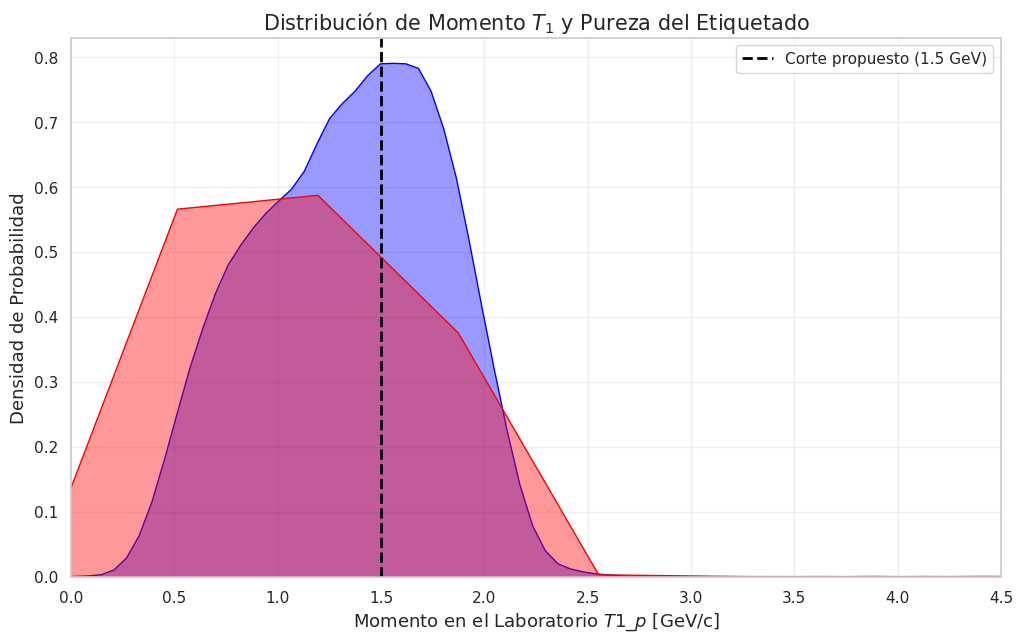

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Preparamos los datos (Leptones como ejemplo, puedes repetir para Kaones)
leptones = df_eda[(df_eda['T1_elecID'] > 0.9) | (df_eda['T1_muonID'] > 0.9)].copy()

# 2. Definimos si el etiquetado fue "Correcto" o "Incorrecto" (basado en la carga)
# Para leptones: carga == target_flavor es el éxito
leptones['etiquetado'] = np.where(leptones['T1_charge'] == leptones['target_flavor'], 
                                  'Correcto (Señal)', 'Incorrecto (Ruido/Cascada)')

# 3. Graficamos la distribución de momento
plt.figure(figsize=(12, 7))

sns.kdeplot(data=leptones, x='T1_p', hue='etiquetado', fill=True, 
            palette={'Correcto (Señal)': 'blue', 'Incorrecto (Ruido/Cascada)': 'red'},
            alpha=0.4, common_norm=False)

# Dibujamos la línea del "corte de tesis"
plt.axvline(1.5, color='black', linestyle='--', linewidth=2, label='Corte propuesto (1.5 GeV)')

plt.title('Distribución de Momento $T_1$ y Pureza del Etiquetado', fontsize=15)
plt.xlabel('Momento en el Laboratorio $T1\_p$ [GeV/c]', fontsize=13)
plt.ylabel('Densidad de Probabilidad', fontsize=13)
plt.xlim(0, 4.5) # Ajusta según tus datos
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:

df_eda.fillna(-999.0, inplace=True)

nulos_restantes = df_eda.isna().sum().sum()
print(f"Nulos restantes en el dataset: {nulos_restantes}")

Nulos restantes en el dataset: 0


In [16]:
cols_a_eliminar = [col for col in df_eda.columns if 'leading' in col]

print(f"Borrando {len(cols_a_eliminar)} variables leading: {cols_a_eliminar}")

# 2. Las eliminamos del DataFrame original
df_eda.drop(columns=cols_a_eliminar, inplace=True)

# 3. Verificamos que ya no existan
print(f"Columnas restantes: {len(df_eda.columns)}")

Borrando 2 variables leading: ['leading_kaon_idx', 'leading_kaon_charge']
Columnas restantes: 193


In [18]:
# Eliminamos las dos variables globales que faltan
cols_globales = ['track_num', 'sum_recoilMassSqrd_total']

# Usamos errors='ignore' por si alguna ya no existe
df_eda.drop(columns=cols_globales, inplace=True, errors='ignore')

print(f"Columnas finales: {len(df_eda.columns)}") 
# Debería imprimir: 191

Columnas finales: 191


In [ ]:
df_eda.drop(columns=['leading_kaon_idx'], inplace=True)

In [ ]:
corr = df_eda.corr(method='spearman')

In [19]:
corr_target = df_eda.drop(columns=['target_flavor']).corrwith(
    df_eda['target_flavor'], 
    method='spearman', 
    numeric_only=True
)

# Ahora sí, saca tu ranking
top_50_vars = corr_target.abs().sort_values(ascending=False).head(50).index.tolist()

In [23]:

print(f"Top 5: {top_50_vars[10:20]}")

Top 5: ['T10_elecID', 'T10_recoilMassSqrd', 'T2_charge', 'T9_recoilMassSqrd', 'T10_kaonID', 'T10_protID', 'T4_nSVDHits', 'T10_EW90', 'T10_cosThetaMissCMS', 'T10_nCDCHits']


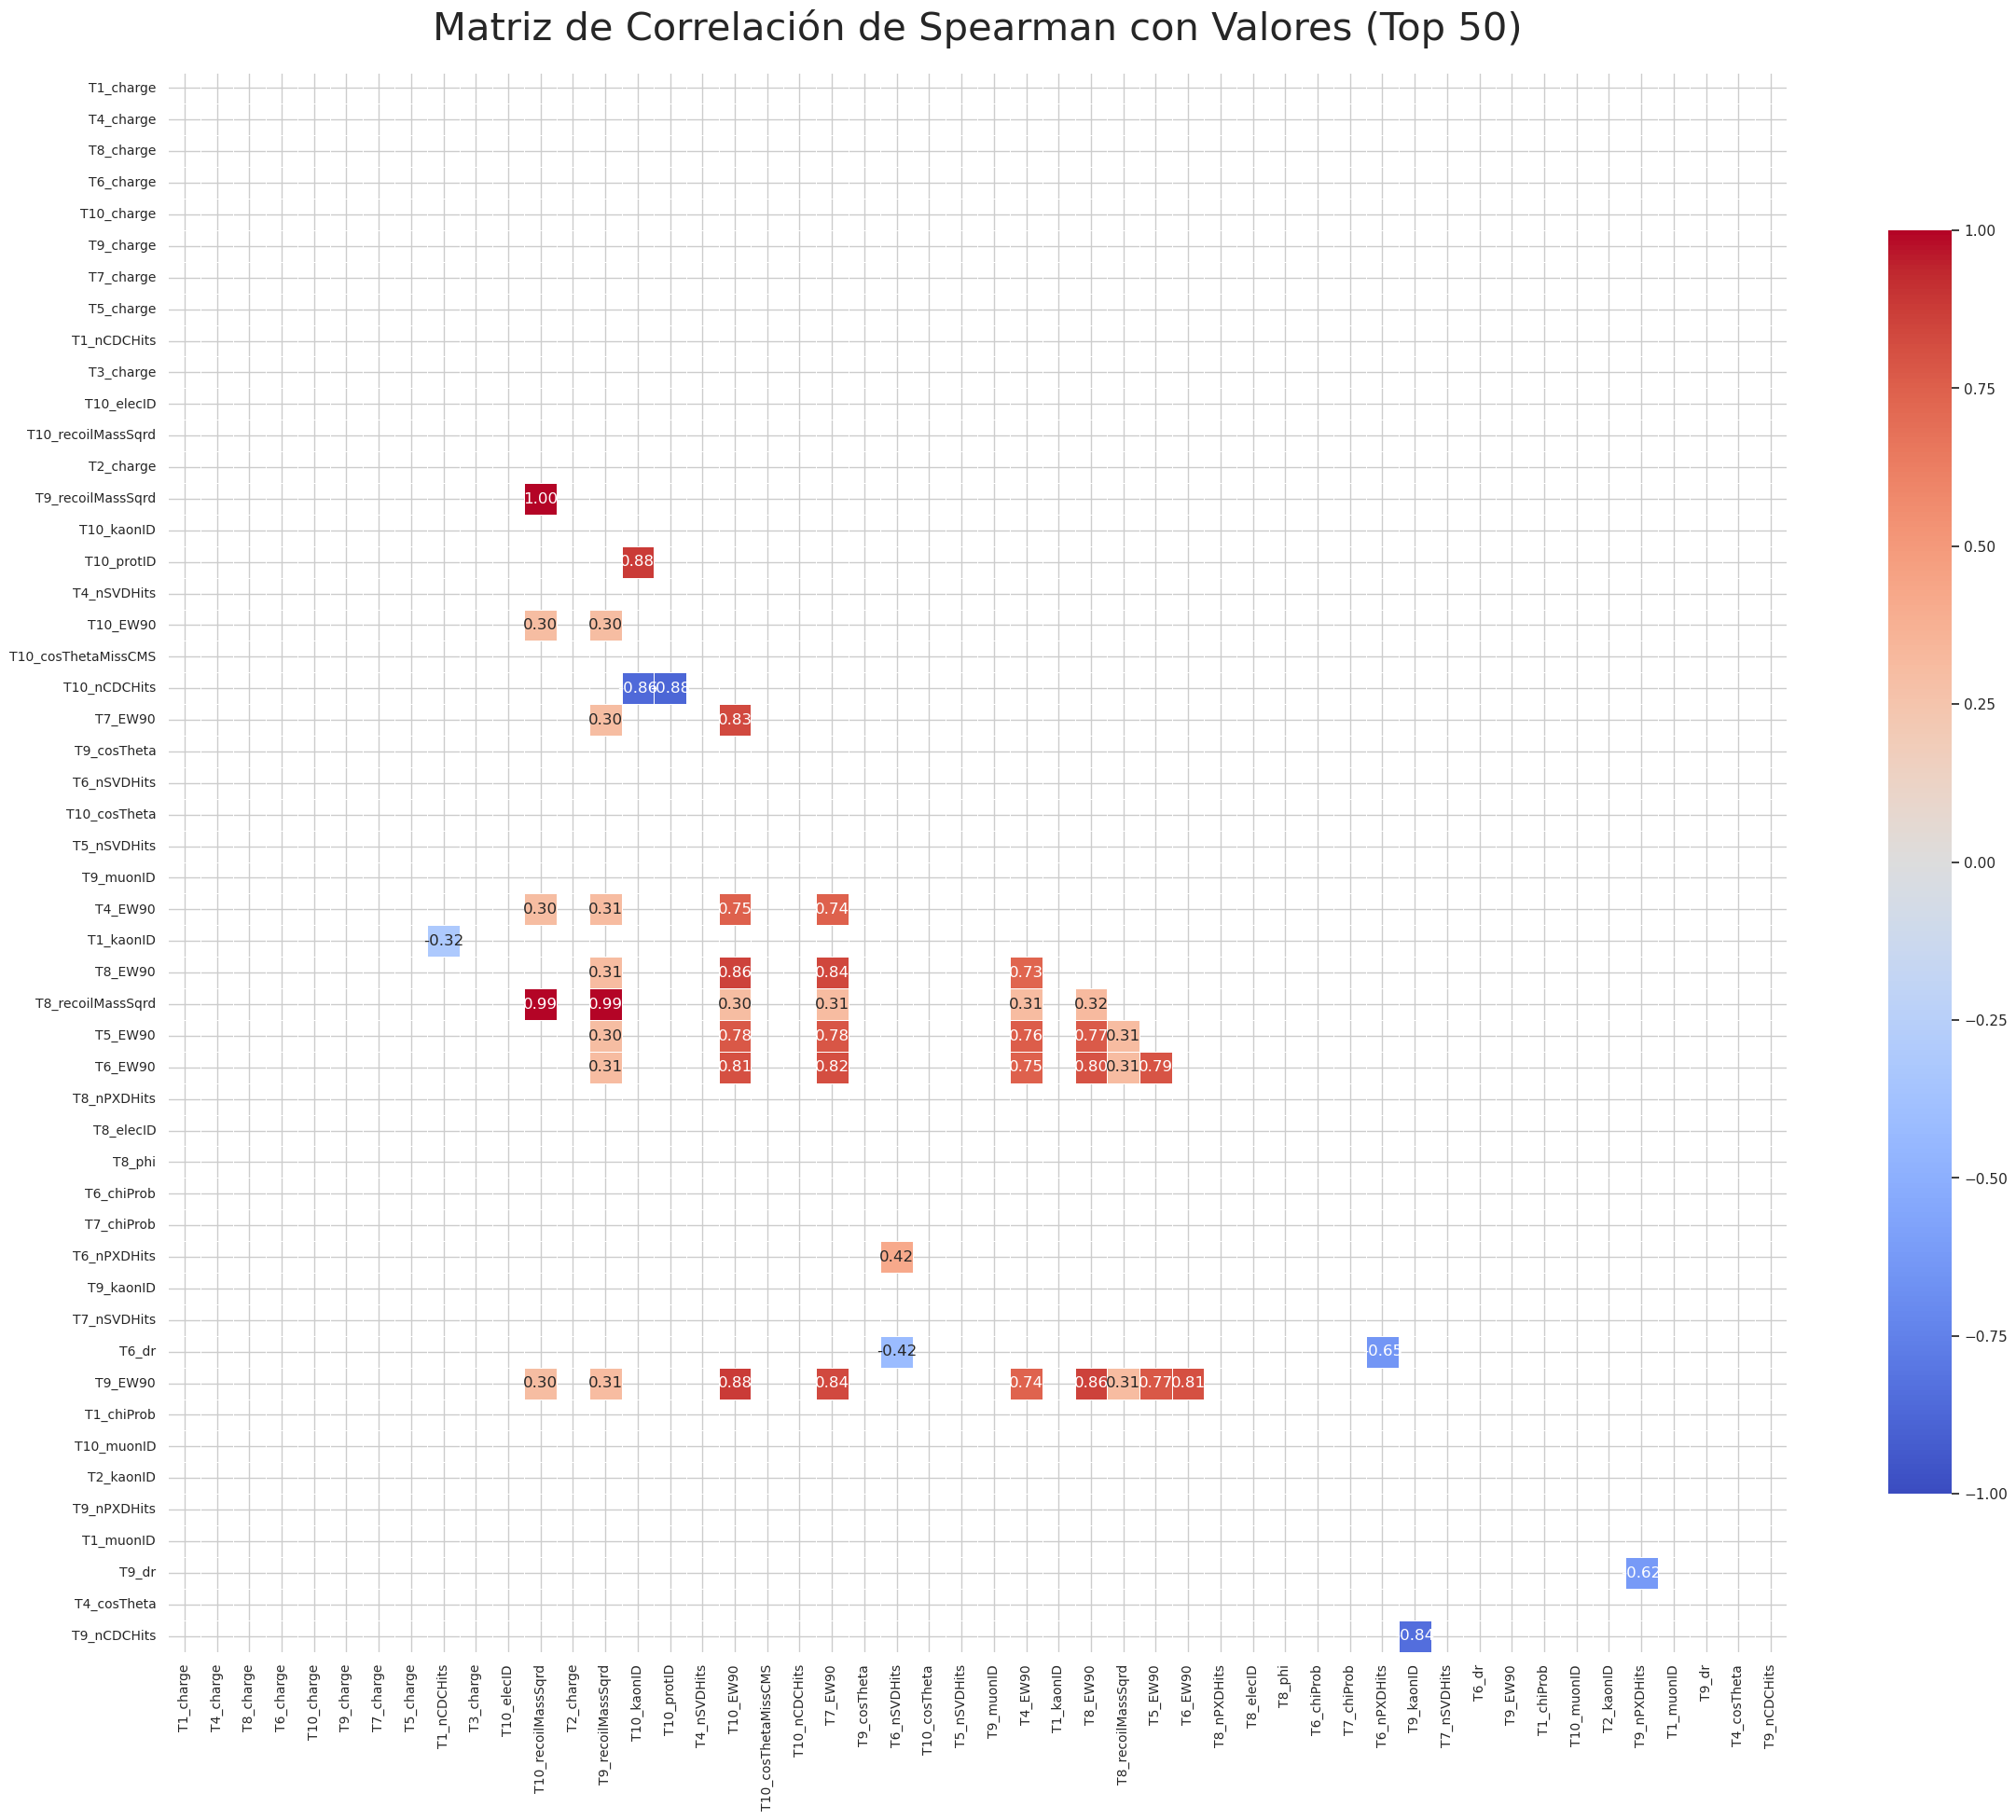

In [29]:
df_top_50 = df_eda[top_50_vars]
matriz_corr_50 = df_top_50.corr(method='spearman')

plt.figure(figsize=(28, 22)) # Aumentamos el lienzo para dar espacio a los números
mask_filtrado = mask | (matriz_corr_50.abs() < 0.3)
sns.heatmap(
    matriz_corr_50, 
    mask=mask_filtrado, 
    cmap='coolwarm', 
    vmax=1, vmin=-1, center=0,
    annot=True,          # <--- ACTIVAMOS LOS NÚMEROS
    fmt=".2f",           # <--- 2 decimales para que no ocupen tanto espacio
    annot_kws={"size": 12}, # <--- Letra pequeña para que quepa en el cuadro
    linewidths=.5, 
    cbar_kws={"shrink": .8}
)

plt.title('Matriz de Correlación de Spearman con Valores (Top 50)', fontsize=30, pad=25)
plt.xticks(fontsize=10, rotation=90)
plt.yticks(fontsize=10)

plt.show()

In [30]:
#Variables VS clase objetivo
from sklearn.feature_selection import mutual_info_classif

df_mi = df.sample(n=500000, random_state=42)
df_mi.fillna(-999.0, inplace=True)

X_mi = df_mi.drop(columns=['target_flavor'])
y_mi = df_mi['target_flavor']

mi_scores = mutual_info_classif(X_mi, y_mi, random_state=42)

df_mi_ranking = pd.DataFrame({
    'Variable': X_mi.columns,
    'Importancia_MI': mi_scores
})

df_mi_ranking = df_mi_ranking.sort_values(by='Importancia_MI', ascending=False).reset_index(drop=True)

print("\n--- TOP 20: VARIABLES CON MAYOR PODER PREDICTIVO (MI) ---")
print(df_mi_ranking.head(20).to_string(index=False))



--- TOP 20: VARIABLES CON MAYOR PODER PREDICTIVO (MI) ---
         Variable  Importancia_MI
        T1_charge        0.068791
            T8_dz        0.055309
      T8_pMissCMS        0.055268
        T8_elecID        0.055246
        T8_kaonID        0.055062
T8_recoilMassSqrd        0.054676
        T8_muonID        0.054517
       T8_chiProb        0.054460
      T8_nSVDHits        0.054234
       T8_cosTPTO        0.054120
       T7_chiProb        0.053978
        T8_charge        0.053971
             T8_p        0.053922
           T8_phi        0.053913
      T8_cosTheta        0.053897
          T8_EW90        0.053822
        T8_protID        0.053780
            T8_dr        0.053772
      T8_nPXDHits        0.053595
T7_recoilMassSqrd        0.053401


In [6]:
#PCA

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


# Extraemos solo las características (sin el target)
df_pca = df.drop(columns=['target_flavor']).sample(n=500000, random_state=42)

df_pca.fillna(-999.0, inplace=True)

In [7]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_pca)


--- RESULTADOS DEL PCA ---
Para retener el 95% de la información necesitas: 13 componentes.
Para retener el 99% de la información necesitas: 21 componentes.


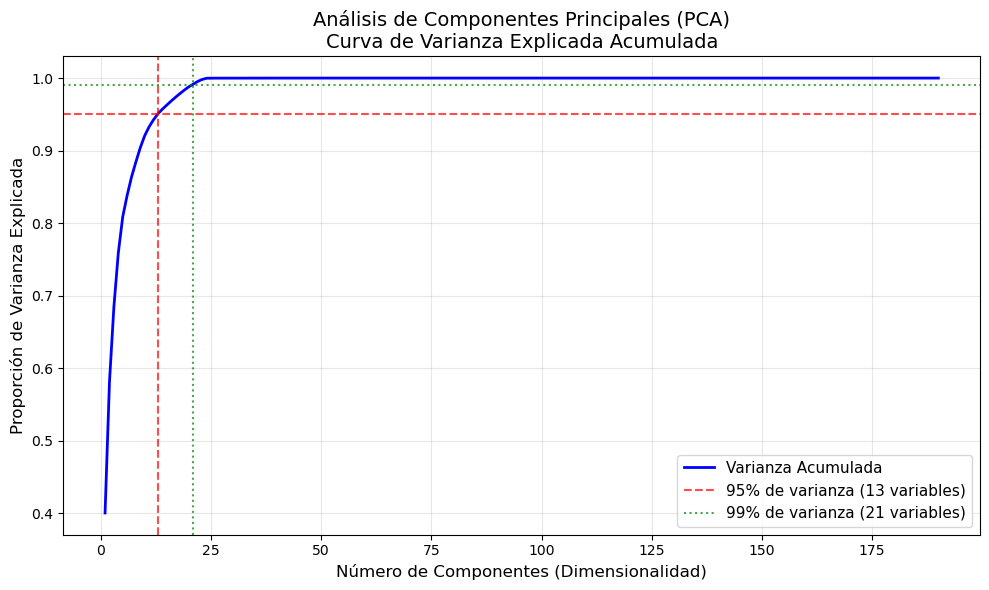

In [8]:
pca = PCA()
pca.fit(X_scaled)

# Suma acumulada de la varianza que explica cada componente
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

# Buscamos matemáticamente cuántos componentes necesitamos para llegar al 95% y 99%
comp_95 = np.argmax(varianza_acumulada >= 0.95) + 1
comp_99 = np.argmax(varianza_acumulada >= 0.99) + 1

print(f"\n--- RESULTADOS DEL PCA ---")
print(f"Para retener el 95% de la información necesitas: {comp_95} componentes.")
print(f"Para retener el 99% de la información necesitas: {comp_99} componentes.")


plt.figure(figsize=(10, 6))

# Graficamos la curva principal
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, 
         color='b', linewidth=2, label='Varianza Acumulada')

# Líneas de referencia para el 95%
plt.axhline(y=0.95, color='r', linestyle='--', alpha=0.7)
plt.axvline(x=comp_95, color='r', linestyle='--', alpha=0.7, 
            label=f'95% de varianza ({comp_95} variables)')

# Líneas de referencia para el 99%
plt.axhline(y=0.99, color='g', linestyle=':', alpha=0.7)
plt.axvline(x=comp_99, color='g', linestyle=':', alpha=0.7, 
            label=f'99% de varianza ({comp_99} variables)')

plt.title('Análisis de Componentes Principales (PCA)\nCurva de Varianza Explicada Acumulada', fontsize=14)
plt.xlabel('Número de Componentes (Dimensionalidad)', fontsize=12)
plt.ylabel('Proporción de Varianza Explicada', fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()

1. Extrayendo datos para la visualización...
2. Generando el gráfico de la física del decaimiento...


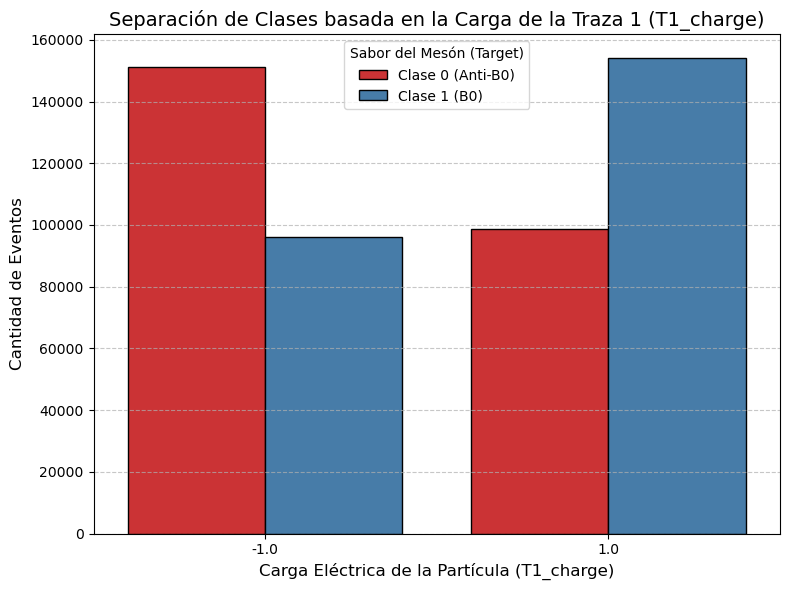

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("1. Extrayendo datos para la visualización...")
# Tomamos solo la variable ganadora y el target de una muestra de 500k eventos
df_vis = df[['T1_charge', 'target_flavor']].sample(n=500000, random_state=42)

# Filtramos los -999.0 en caso de que algún evento extremo no tenga ni una sola traza
df_vis = df_vis[df_vis['T1_charge'] != -999.0]

print("2. Generando el gráfico de la física del decaimiento...")
plt.figure(figsize=(8, 6))

# Creamos el gráfico de barras agrupado por el target
sns.countplot(data=df_vis, x='T1_charge', hue='target_flavor', palette='Set1', edgecolor='black')

# Personalizamos títulos y etiquetas
plt.title('Separación de Clases basada en la Carga de la Traza 1 (T1_charge)', fontsize=14)
plt.xlabel('Carga Eléctrica de la Partícula (T1_charge)', fontsize=12)
plt.ylabel('Cantidad de Eventos', fontsize=12)

# Hacemos la leyenda más descriptiva para tu tesis
plt.legend(title='Sabor del Mesón (Target)', labels=['Clase 0 (Anti-B0)', 'Clase 1 (B0)'])

# Añadimos una cuadrícula suave de fondo para que se lean mejor las alturas
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()